[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-2/blob/main/notebooks/ch50_LabCh50_Diffusion_By_Hand.ipynb)

**The Why Book of Deep Learning, Part 2** by Dr. Philemon Paul Daniel

**Chapter 50: Diffusion by Hand** (Part XI: Imagining in Depth).

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-2/read.html?ch=50](https://www.micyaai.com/books/why-deep-learning-2/read.html?ch=50)
* Part 1 of the book and its notebooks: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-2](https://github.com/phildani7/why-book-of-deep-learning-part-2)

Tested with TensorFlow 2.21 and Keras 3.14 on a laptop CPU (about five minutes or less). In Colab:
*Runtime > Run all*. It runs on the free CPU runtime; a GPU runtime works too and is usually faster, but the
printed timings and some last digits will differ from the saved outputs.

---


# Lab Ch50 - Diffusion by hand
## Destroy data with noise, teach a network to undo one small step, then run it backwards

This lab goes with **Chapter 50** of *The Why Book of Deep Learning, Part 2*.

Part 1 of the book (Chapter 29) showed a diffusion model from above. Here you build one from the
schedule up, twice. **Part A** works on 8,000 points in a plane, where every stage can be plotted and
checked with a number: the noise schedule, the forward process, the network, the loss at each noise
level, and the sampler. **Part B** runs exactly the same code on small MNIST digits with a U-Net.

| Piece | Part A: points | Part B: digits |
|---|---|---|
| data | two interleaved moons, 2 numbers per point | MNIST shrunk to 16 × 16, scaled to -1 ... 1 |
| schedule | linear, 1,000 steps, 0.0001 to 0.02 (the 2020 DDPM paper) | the same |
| network | an MLP, 4 hidden layers of 128, time joined to the input | Chapter 47's U-Net plus a time embedding |
| target | the noise that was added | the same |
| sampler | ancestral, 1,000 steps | the same function |

### What you will be able to do afterwards

| Skill | Where |
|---|---|
| Build a noise schedule and read its signal weight, noise weight and signal-to-noise ratio | Steps 3 and 4 |
| Show that 500 small noising steps equal one closed-form jump | Step 5 |
| Give a network the time as a sinusoidal embedding, and count the parameters | Steps 6 and 7 |
| Write the five-line training step and say what loss an untrained network should score | Steps 8 and 9 |
| Read the loss one noise level at a time | Step 10 |
| Explain with numbers why one big jump fails and many small steps work | Steps 11 and 12 |
| Show that the training loss cannot tell a good sampler from a poor one | Step 13 |
| Say what the fresh noise in the sampler is for, and what the time input is for | Steps 14 and 15 |
| Show why you cannot skip steps without changing the arithmetic | Step 16 |
| Train and sample a small image diffusion model and judge it honestly | Steps 17 to 21 |

### The rule of this lab: predict, then run

Every step asks you to **write down a prediction before you run the cell**. A wrong prediction that you
understand afterwards is worth more than a right one you guessed.

> **Runtime:** three to four minutes on a laptop CPU. Step 9 (about 25 seconds), Step 15 (the same again)
> and Step 19 (90 seconds to two minutes) are the long training runs. No GPU is needed. The only download is MNIST
> from `keras.datasets`.

> **Honest scale:** this is a miniature. The image model has about 129,000 parameters and trains for a
> minute and a half on 16 × 16 digits. Its samples are rough, and Step 20 says so. The image model of the
> 2020 DDPM paper had tens of millions of parameters and trained for hundreds of thousands of steps. The **method** in this
> notebook is the real one; the **results** are small-model results and are for comparing runs inside this
> notebook with each other.

> **Reused later:** Chapters 51 and 52 copy `make_points`, `make_schedule`, `TimeEmbedding`,
> `build_denoiser`, `q_sample`, `train_denoiser` and `sample` from this notebook unchanged.

---
## Step 1 - Imports and one seed

In [1]:
import os, time
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 50
keras.utils.set_random_seed(SEED)
np.set_printoptions(precision=4, suppress=True, linewidth=120)
t_start = time.time()
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

TensorFlow 2.21.0 | Keras 3.14.1


---
# Part A - Diffusion on points you can plot

## Step 2 - The data: two moons

An image is a point in a space with thousands of axes, which nobody can draw. So we start with data that
has **two** axes. Each "image" is one point (x, y), and the "data set of images" is a cloud of points
shaped like two interleaved crescents. Everything a diffusion model does to an image it does to these
points, and here you can watch.

`make_points` also returns which moon each point belongs to (0 or 1). This chapter ignores the label;
Chapter 51 uses it.

> **Predict:** the points are centred and scaled so that most of them lie between -2 and 2. Pure noise
> (mean 0, standard deviation 1) covers about the same region. Why would we want the data and the noise
> to live on the same scale?

X: (8000, 2) float32 | labels: [4000 4000]
mean: [0.005 0.004] | std: [0.965 0.552] | min: [-1.82 -1.01] | max: [1.88 1.  ]


2,000 fresh real points            off 0.009 | miss 0.017 | further than 0.1 from any moon:   0.0% | std [0.97 0.55]


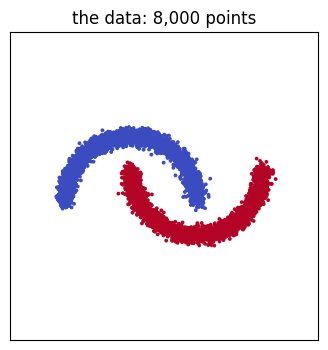

In [2]:
def make_points(n=8000, seed=0):
    """Two interleaved moons. Returns (points of shape (n, 2) float32, moon label of shape (n,))."""
    rng = np.random.default_rng(seed)
    half = n // 2
    a = rng.uniform(0, np.pi, half)
    b = rng.uniform(0, np.pi, n - half)
    upper = np.stack([np.cos(a), np.sin(a)], axis=1)                 # moon 0: an arch
    lower = np.stack([1 - np.cos(b), 0.5 - np.sin(b)], axis=1)       # moon 1: a bowl, shifted right
    x = np.concatenate([upper, lower]) + rng.normal(0, 0.06, (n, 2)) # a little thickness
    y = np.concatenate([np.zeros(half, dtype="int32"), np.ones(n - half, dtype="int32")])
    x = (x - np.array([0.5, 0.25])) / 0.9                            # centre, and scale to roughly unit size
    order = rng.permutation(n)
    return x[order].astype("float32"), y[order]

def nearest_dist(a, b):
    """For every point in a, the distance to its nearest point in b."""
    d2 = ((a[:, None, :] - b[None, :, :]) ** 2).sum(-1)
    return np.sqrt(d2.min(axis=1))

def lims(ax, r=2.6):
    ax.set_xlim(-r, r); ax.set_ylim(-r, r); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])

X, Y = make_points(8000, seed=0)             # the training set
X_REAL, _ = make_points(2000, seed=1)        # fresh points from the same moons, never trained on
X_REAL2, _ = make_points(2000, seed=2)       # and a second fresh set, for a yardstick
print("X:", X.shape, X.dtype, "| labels:", np.bincount(Y))
print("mean:", X.mean(0).round(3), "| std:", X.std(0).round(3), "| min:", X.min(0).round(2), "| max:", X.max(0).round(2))

# two yardsticks used all through Part A (smaller is better for both):
#   off  = how far a generated point is from the nearest training point   (is it on a moon?)
#   miss = how far a real point is from the nearest generated point        (is every part of the moons covered?)
def score(samples, name):
    off = nearest_dist(samples, X).mean()
    miss = nearest_dist(X_REAL, samples).mean()
    far = (nearest_dist(samples, X) > 0.1).mean()
    print(f"{name:34s} off {off:.3f} | miss {miss:.3f} | further than 0.1 from any moon: {100 * far:5.1f}% | std {samples.std(0).round(2)}")
    return off, miss, far

REAL_SCORE = score(X_REAL2, "2,000 fresh real points")

fig, ax = plt.subplots(figsize=(4, 4))
ax.scatter(X[:, 0], X[:, 1], s=3, c=Y, cmap="coolwarm"); lims(ax); ax.set_title("the data: 8,000 points"); plt.show()

### Why we see this

The cloud has mean close to (0, 0) and standard deviations of about 0.96 and 0.55. The forward process is
going to end at pure Gaussian noise with mean 0 and standard deviation 1, and the sampler is going to
**start** from that noise. If the data sat at, say, 0 to 255, the noise would be a speck beside it and the
schedule's numbers would mean something quite different. For images the convention is to scale pixels to
**-1 ... 1**, and Part B does that.

The line for "fresh real points" is the yardstick: real points land about 0.012 from the nearest training
point, and none is further than 0.1 from a moon. A perfect generator would score the same.

---
## Step 3 - The noise schedule

The forward process has T small steps. At step t it does two things to every number:

1. **shrink** it slightly: multiply by √(1 − β<sub>t</sub>), a number a little below 1;
2. **add noise**: Gaussian noise with variance β<sub>t</sub>.

The list of β values is the **noise schedule**. The 2020 DDPM paper used T = 1,000 and a straight line from
β = 0.0001 to β = 0.02. The shrink is there so that the numbers keep the same overall size: what the
shrink takes away in variance, the noise puts back.

`make_schedule` returns arrays of length T + 1 so that **index t means "after t steps"** and index 0 is the
clean data. That one decision removes most off-by-one mistakes later.

> **Predict:** each step keeps the fraction (1 − β) of the signal's variance. After all 1,000 steps the
> fraction left is the product of 1,000 numbers between 0.98 and 0.9999. Is that closer to 0.5, 0.01 or
> 0.00004?

In [3]:
def make_schedule(T=1000, kind="linear"):
    """A noise schedule. Every array has length T + 1; index t = after t noising steps; index 0 = clean data.
    kind = "linear": beta from 0.0001 to 0.02 when T = 1000 (DDPM, 2020), scaled by 1000 / T for other T.
    kind = "cosine": the cosine schedule (2021), which sets the signal left directly and derives beta from it."""
    if kind == "linear":
        beta = np.linspace(1e-4, 0.02, T) * (1000.0 / T)
    elif kind == "cosine":
        s = 0.008
        u = np.arange(T + 1) / T
        f = np.cos((u + s) / (1 + s) * np.pi / 2) ** 2
        beta = np.clip(1 - f[1:] / f[:-1], 0.0, 0.999)
    else:
        raise ValueError(kind)
    beta = np.concatenate([[0.0], beta])                 # beta[0] = 0: step 0 adds nothing
    alpha = 1.0 - beta                                   # fraction of variance kept by one step
    abar = np.cumprod(alpha)                             # fraction of variance kept after t steps ("alpha-bar")
    abar_prev = np.concatenate([[1.0], abar[:-1]])
    one_minus = np.maximum(1.0 - abar, 1e-20)
    return {
        "T": T, "kind": kind, "beta": beta, "alpha": alpha, "abar": abar,
        "signal": np.sqrt(abar),                         # weight on the clean data at step t
        "noise": np.sqrt(1.0 - abar),                    # weight on the noise at step t
        # the three numbers the sampler needs at step t (Step 12 explains them):
        "to_clean": np.sqrt(abar_prev) * beta / one_minus,           # weight on the guess of the clean data
        "to_current": np.sqrt(alpha) * (1.0 - abar_prev) / one_minus,  # weight on the current noisy point
        "sigma": np.sqrt(beta * (1.0 - abar_prev) / one_minus),      # size of the fresh noise added back
    }

SCHED = make_schedule(1000, "linear")
T = SCHED["T"]
print("array length:", len(SCHED["beta"]), "(T + 1)")
print(f"{'t':>5} {'beta':>9} {'kept by this step':>18} {'kept after t steps':>19}")
for t in (0, 1, 2, 10, 100, 500, 1000):
    print(f"{t:5d} {SCHED['beta'][t]:9.5f} {SCHED['alpha'][t]:18.5f} {SCHED['abar'][t]:19.6f}")

array length: 1001 (T + 1)
    t      beta  kept by this step  kept after t steps
    0   0.00000            1.00000            1.000000
    1   0.00010            0.99990            0.999900
    2   0.00012            0.99988            0.999780
   10   0.00028            0.99972            0.998105
  100   0.00207            0.99793            0.897018
  500   0.01004            0.98996            0.078587
 1000   0.02000            0.98000            0.000040


### Why we see this

After 1,000 steps 0.00004 of the signal's variance is left: four parts in a hundred thousand. No single
step did much (the harshest keeps 98%), yet the product of a thousand of them is as good as nothing.
That is the forward process in one line: many small losses, multiplied.

---
## Step 4 - Signal weight, noise weight and the one dial behind every schedule

The column "kept after t steps" is called ᾱ<sub>t</sub> (alpha-bar). Its square root is the **signal
weight** and √(1 − ᾱ<sub>t</sub>) is the **noise weight**. The two weights squared always add up to 1.
Their ratio squared is the **signal-to-noise ratio**, SNR = ᾱ / (1 − ᾱ).

A second schedule, the **cosine** schedule (2021), picks ᾱ directly as a squared cosine that falls
gently, instead of picking β.

> **Predict:** halfway through, at t = 500, how much signal weight does the linear schedule have left:
> 0.7, 0.5 or 0.3? And at which step does the noise first outweigh the signal (SNR below 1)?


linear schedule
     t  signal weight  noise weight  squares add to          SNR
     0         1.0000        0.0000          1.0000       1e+300
   250         0.7239        0.6899          1.0000        1.101
   500         0.2803        0.9599          1.0000      0.08529
   750         0.0579        0.9983          1.0000     0.003362
  1000         0.0064        1.0000          1.0000    4.036e-05
noise outweighs signal from step 260; signal weight is below 0.1 from step 674 (the last 327 steps, 32.7% of the schedule)

cosine schedule
     t  signal weight  noise weight  squares add to          SNR
     0         1.0000        0.0000          1.0000       1e+300
   250         0.9203        0.3911          1.0000        5.536
   500         0.7027        0.7114          1.0000       0.9757
   750         0.3798        0.9251          1.0000       0.1686
  1000         0.0000        1.0000          1.0000    2.429e-09
noise outweighs signal from step 497; signal weight is below 0.

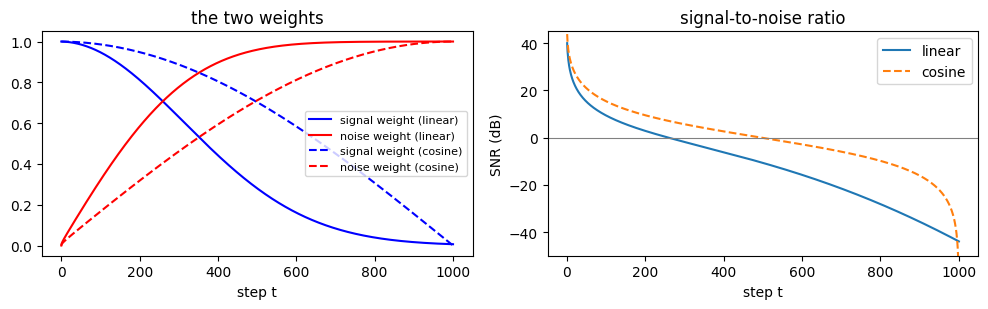

In [4]:
COS = make_schedule(1000, "cosine")
marks = (0, 250, 500, 750, 1000)
for name, S in (("linear", SCHED), ("cosine", COS)):
    print(f"\n{name} schedule")
    print(f"{'t':>6} {'signal weight':>14} {'noise weight':>13} {'squares add to':>15} {'SNR':>12}")
    for t in marks:
        sg, nz = S["signal"][t], S["noise"][t]
        snr = S["abar"][t] / max(1 - S["abar"][t], 1e-300)
        print(f"{t:6d} {sg:14.4f} {nz:13.4f} {sg ** 2 + nz ** 2:15.4f} {snr:12.4g}")
    cross = int(np.argmax(S["abar"] < 0.5))                      # first step with SNR below 1
    faint = int(np.argmax(S["signal"] < 0.1))                    # first step with signal weight below 0.1
    print(f"noise outweighs signal from step {cross}; signal weight is below 0.1 from step {faint}"
          f" (the last {T - faint + 1} steps, {100 * (T - faint + 1) / T:.1f}% of the schedule)")

snr_db = 10 * np.log10(SCHED["abar"][1:] / (1 - SCHED["abar"][1:]))
print(f"\nlinear schedule, SNR in decibels: step 1 = {snr_db[0]:.1f} dB, step 1000 = {snr_db[-1]:.1f} dB")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for S, ls in ((SCHED, "-"), (COS, "--")):
    ax[0].plot(S["signal"], "b" + ls, label=f"signal weight ({S['kind']})")
    ax[0].plot(S["noise"], "r" + ls, label=f"noise weight ({S['kind']})")
    ax[1].plot(np.arange(1, T + 1), 10 * np.log10(S["abar"][1:] / np.maximum(1 - S["abar"][1:], 1e-12)), ls, label=S["kind"])
ax[0].set_xlabel("step t"); ax[0].legend(fontsize=8); ax[0].set_title("the two weights")
ax[1].axhline(0, color="grey", lw=0.8); ax[1].set_ylim(-50, 45); ax[1].set_xlabel("step t"); ax[1].set_ylabel("SNR (dB)")
ax[1].legend(); ax[1].set_title("signal-to-noise ratio")
plt.tight_layout(); plt.show()

### Why we see this

With the linear schedule the signal weight is 0.72 at step 250, 0.28 at step 500, 0.06 at step 750 and
0.006 at step 1,000. Noise outweighs signal from step 260, a quarter of the way in, and for the last
third of the schedule (from step 674) the signal weight is under 0.1: those steps are spent on
pictures that are already nearly static.

The cosine schedule falls more evenly: 0.92, 0.70, 0.38, and it crosses SNR = 1 at step 497, almost
exactly halfway. Only its last 65 steps have a signal weight under 0.1. That is what "the cosine
schedule wastes fewer steps" means. Its authors proposed it for small images, where the linear schedule
destroys the picture too early.

Both schedules are the same kind of object: **a falling curve of SNR against t**. Every other schedule
you will meet is another such curve.

---
## Step 5 - The forward process: a thousand small steps, or one jump

Noising step by step means: shrink, add noise, repeat. There is a shortcut. A sum of Gaussian noises is
a Gaussian noise, so t steps collapse into one:

**noisy point at step t = (signal weight at t) × clean point + (noise weight at t) × fresh noise**

`q_sample` is that line. This cell checks it two ways. First, arithmetic: the product of the first t
shrinks must equal the signal weight. Second, statistics: push the 8,000 points through 500 real steps
and compare the cloud with the one-jump cloud.

> **Predict:** the two clouds at t = 500 are made with different random numbers, so no point matches its
> twin. What should match?

product of the first 500 shrinks: 0.280334 | signal weight at 500: 0.280334

    t                  mean x   mean y    std x    std y
  100   step by step    0.007    0.003    0.969    0.610
  100       one jump    0.009    0.007    0.967    0.612
              theory    0.000    0.000    0.969    0.613
  250   step by step    0.003   -0.006    0.985    0.796
  250       one jump    0.002   -0.003    0.982    0.796
              theory    0.000    0.000    0.982    0.797
  500   step by step   -0.002    0.001    1.000    0.970
  500       one jump    0.007    0.004    1.004    0.972
              theory    0.000    0.000    0.997    0.972
 1000   step by step   -0.009   -0.019    0.996    0.978
 1000       one jump   -0.004    0.004    0.993    1.000
              theory    0.000    0.000    1.000    1.000


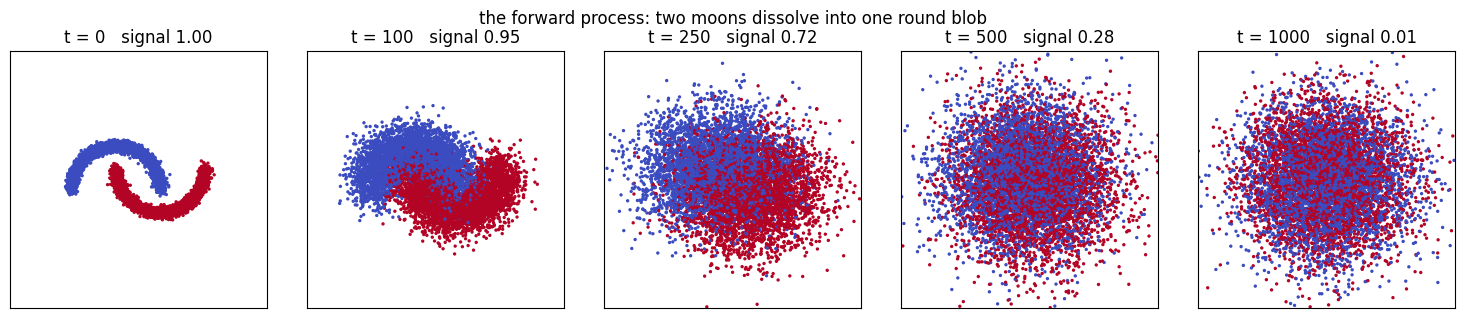

In [5]:
def q_sample(x0, t, eps, sched):
    """The forward process in one jump. x0: clean data (n, ...); t: integer steps (n,); eps: noise shaped like x0."""
    shape = (-1,) + (1,) * (x0.ndim - 1)
    sg = sched["signal"][t].reshape(shape).astype("float32")
    nz = sched["noise"][t].reshape(shape).astype("float32")
    return sg * x0 + nz * eps

rng = np.random.default_rng(SEED)

# check 1: arithmetic
shrink = np.cumprod(np.sqrt(SCHED["alpha"]))
assert np.allclose(shrink, SCHED["signal"])
print("product of the first 500 shrinks:", round(float(shrink[500]), 6), "| signal weight at 500:", round(float(SCHED["signal"][500]), 6))

# check 2: statistics, and keep some snapshots for the plot
x = X.copy()
slow = {0: x.copy()}
for t in range(1, 1001):
    x = np.sqrt(SCHED["alpha"][t]) * x + np.sqrt(SCHED["beta"][t]) * rng.standard_normal(x.shape)
    if t in (100, 250, 500, 1000):
        slow[t] = x.copy()
print(f"\n{'t':>5} {'':>14} {'mean x':>8} {'mean y':>8} {'std x':>8} {'std y':>8}")
for t in (100, 250, 500, 1000):
    jump = q_sample(X, np.full(len(X), t), rng.standard_normal(X.shape).astype("float32"), SCHED)
    theory = np.sqrt(SCHED["abar"][t] * X.var(0) + 1 - SCHED["abar"][t])
    for name, c in (("step by step", slow[t]), ("one jump", jump)):
        print(f"{t:5d} {name:>14} {c.mean(0)[0]:8.3f} {c.mean(0)[1]:8.3f} {c.std(0)[0]:8.3f} {c.std(0)[1]:8.3f}")
    print(f"{'':5} {'theory':>14} {0:8.3f} {0:8.3f} {theory[0]:8.3f} {theory[1]:8.3f}")

fig, ax = plt.subplots(1, 5, figsize=(15, 3.2))
for a, t in zip(ax, (0, 100, 250, 500, 1000)):
    a.scatter(slow[t][:, 0], slow[t][:, 1], s=2, c=Y, cmap="coolwarm"); lims(a, 3.2)
    a.set_title(f"t = {t}   signal {SCHED['signal'][t]:.2f}")
plt.suptitle("the forward process: two moons dissolve into one round blob"); plt.tight_layout(); plt.show()

### Why we see this

The product of the shrinks is the signal weight, exactly. And the two clouds agree in every statistic to
about two decimal places, which is as close as 8,000 random points can agree. They are two draws from the
**same distribution**. Training never needs the slow version: to make a training example at step 731 you
do one multiplication and one addition.

In the pictures the moons are still plain at t = 100 (signal 0.95), smudged at 250, a lump at 500, and at
1,000 a round Gaussian blob with both colours mixed evenly. The standard deviations finish at about 1.00
and 1.00: the blob has forgotten that the data was wider than it was tall. **Nothing was learnt to do this.**
The forward process has no weights.

---
## Step 6 - Telling the network the time

The network will be handed a noisy point and asked what noise is in it. It also needs to know **how much**
noise to look for, which means it needs t. A bare integer from 1 to 1,000 is a poor input for a network
(Chapter 34 explains why), so t is turned into a vector of sines and cosines at many frequencies, exactly
as a transformer's positions are.

> **Predict:** the embedding has 32 numbers, 16 sines then 16 cosines. Every number lies between -1 and 1.
> Which entries change fast as t goes from 500 to 501, the first few or the last few?

shape: (4, 32) | trainable weights: 0
t = 500, first 4 sines: [-0.4678 -1.      0.8595  0.8131] | last 4 sines: [0.4794 0.2775 0.1575 0.0888]
t = 501, first 4 sines: [-0.9965 -0.847   0.9758  0.9032] | last 4 sines: [0.4803 0.278  0.1578 0.089 ]


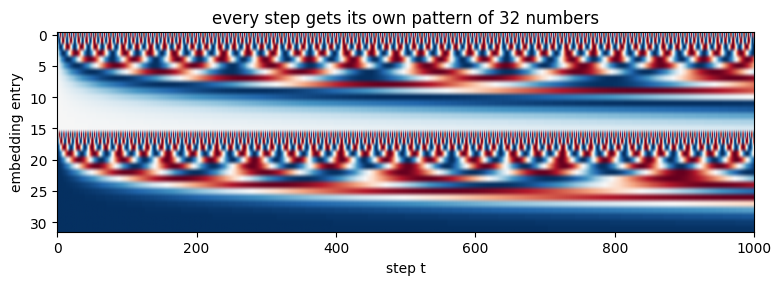

In [6]:
class TimeEmbedding(layers.Layer):
    """Integer step t, shape (batch,)  ->  sinusoidal vector, shape (batch, dim). No weights."""
    def __init__(self, dim=32, max_period=10000.0, **kwargs):
        super().__init__(**kwargs)
        self.dim = dim
        self.max_period = max_period

    def call(self, t):
        ops = keras.ops
        t = ops.cast(ops.reshape(t, (-1, 1)), "float32")
        half = self.dim // 2
        freqs = ops.exp(-np.log(self.max_period) * ops.arange(half, dtype="float32") / half)
        angles = t * ops.reshape(freqs, (1, -1))
        return ops.concatenate([ops.sin(angles), ops.cos(angles)], axis=-1)

    def get_config(self):
        return {**super().get_config(), "dim": self.dim, "max_period": self.max_period}

emb = np.array(TimeEmbedding(32)(np.array([1, 500, 501, 1000])))
print("shape:", emb.shape, "| trainable weights:", len(TimeEmbedding(32).weights))
print("t = 500, first 4 sines:", emb[1, :4], "| last 4 sines:", emb[1, 12:16])
print("t = 501, first 4 sines:", emb[2, :4], "| last 4 sines:", emb[2, 12:16])

table = np.array(TimeEmbedding(32)(np.arange(0, 1001)))
plt.figure(figsize=(9, 2.6)); plt.imshow(table.T, aspect="auto", cmap="RdBu", vmin=-1, vmax=1)
plt.xlabel("step t"); plt.ylabel("embedding entry"); plt.title("every step gets its own pattern of 32 numbers"); plt.show()

### Why we see this

The first entries swing wildly between neighbouring steps and the last ones barely move. Fast entries
tell close steps apart; slow ones tell the network roughly where in the schedule it is. The layer has
no weights: it is a fixed way of writing a number down.

---
## Step 7 - The network, counted

The noise predictor is an MLP. In: the noisy point (2 numbers) joined to the time embedding (32 numbers).
Out: 2 numbers, its guess of the noise. The output layer has **no activation**, because noise is any real
number, positive or negative.

> **Predict:** 34 inputs, four hidden layers of 128, 2 outputs. A Dense layer has (inputs + 1) × units
> parameters. Work out the total before you run the cell.

In [7]:
def build_denoiser(dim=2, width=128, depth=4, emb_dim=32, use_time=True, name="denoiser"):
    """An MLP that predicts the noise in x_t. Inputs: x_t of shape (dim,), and the integer step t.
    use_time=False multiplies the time embedding by zero (for the experiment in Step 15)."""
    x_in = layers.Input(shape=(dim,), name="x_t")
    t_in = layers.Input(shape=(), dtype="int32", name="t")
    e = TimeEmbedding(emb_dim, name="time_embedding")(t_in)
    if not use_time:
        e = layers.Rescaling(0.0, name="time_switched_off")(e)
    h = layers.Concatenate(name="join")([x_in, e])
    for i in range(depth):
        h = layers.Dense(width, activation="swish", name=f"dense{i + 1}")(h)
    out = layers.Dense(dim, name="noise")(h)                       # no activation: noise has no range
    return keras.Model([x_in, t_in], out, name=name)

first = (2 + 32 + 1) * 128
hidden = 3 * (128 + 1) * 128
last = (128 + 1) * 2
MLP_HAND = first + hidden + last
print(f"first layer   (2 + 32 + 1) x 128 = {first:,}")
print(f"three more    3 x (128 + 1) x 128 = {hidden:,}")
print(f"output layer  (128 + 1) x 2 = {last:,}")
print(f"hand count  : {MLP_HAND:,}")

keras.utils.set_random_seed(SEED)
denoiser = build_denoiser()
denoiser.summary(line_length=88)
assert denoiser.count_params() == MLP_HAND == 54_274
print("output shape:", denoiser.output_shape, "= the input's shape: one noise guess per coordinate")

first layer   (2 + 32 + 1) x 128 = 4,480
three more    3 x (128 + 1) x 128 = 49,536
output layer  (128 + 1) x 2 = 258
hand count  : 54,274


Model: "denoiser"

┏━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)            ┃ Output Shape         ┃      Param # ┃ Connected to         ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━┩
│ t (InputLayer)          │ (None)               │            0 │ -                    │
├─────────────────────────┼──────────────────────┼──────────────┼──────────────────────┤
│ x_t (InputLayer)        │ (None, 2)            │            0 │ -                    │
├─────────────────────────┼──────────────────────┼──────────────┼──────────────────────┤
│ time_embedding          │ (None, 32)           │            0 │ t[0][0]              │
│ (TimeEmbedding)         │                      │              │                      │
├─────────────────────────┼──────────────────────┼──────────────┼──────────────────────┤
│ join (Concatenate)      │ (None, 34)           │            0 │ x_t[0][0],           │
│                         │                      │              │ time_embedding[0][0] │
├─────────────────────────┼──────────────────────┼──────────────┼──────────────────────┤
│ dense1 (Dense)          │ (None, 128)          │        4,480 │ join[0][0]           │
├─────────────────────────┼──────────────────────┼──────────────┼──────────────────────┤
│ dense2 (Dense)          │ (None, 128)          │       16,512 │ dense1[0][0]         │
├─────────────────────────┼──────────────────────┼──────────────┼──────────────────────┤
│ dense3 (Dense)          │ (None, 128)          │       16,512 │ dense2[0][0]         │
├─────────────────────────┼──────────────────────┼──────────────┼──────────────────────┤
│ dense4 (Dense)          │ (None, 128)          │       16,512 │ dense3[0][0]         │
├─────────────────────────┼──────────────────────┼──────────────┼──────────────────────┤
│ noise (Dense)           │ (None, 2)            │          258 │ dense4[0][0]         │
└─────────────────────────┴──────────────────────┴──────────────┴──────────────────────┘

 Total params: 54,274 (212.01 KB)

 Trainable params: 54,274 (212.01 KB)

 Non-trainable params: 0 (0.00 B)

output shape: (None, 2) = the input's shape: one noise guess per coordinate


### Why we see this

4,480 + 49,536 + 258 = **54,274**. The time embedding adds 32 × 128 = 4,096 weights to the first layer
and nothing anywhere else. The output has the shape of the input. That is true of every diffusion
network, whatever its insides: a noise guess for every number it was given.

---
## Step 8 - One training step, by hand

The whole training step is five lines: pick clean data, pick a random step for each example, draw noise,
mix with `q_sample`, and score the network's noise guess with mean squared error.

> **Predict:** the noise has mean 0 and variance 1. A network that always answers "no noise at all, (0, 0)"
> scores what mean squared error? And an untrained network with small random weights?

In [8]:
rng = np.random.default_rng(SEED)
x0 = X[:512]                                                    # 1. some clean data
t = rng.integers(1, T + 1, size=len(x0))                        # 2. a random step for every example
eps = rng.standard_normal(x0.shape).astype("float32")           # 3. the noise
x_t = q_sample(x0, t, eps, SCHED)                               # 4. mix
loss = np.mean((denoiser.predict([x_t, t], verbose=0) - eps) ** 2)   # 5. how wrong is the noise guess?

print("steps drawn (first 8):", t[:8])
print(f"loss of an untrained network: {loss:.3f}")
print(f"loss of 'always answer zero': {np.mean(eps ** 2):.3f}")
print(f"loss of 'the input is the noise' (answer x_t): {np.mean((x_t - eps) ** 2):.3f}")

steps drawn (first 8): [782 788 715 834 824 548 243 974]
loss of an untrained network: 0.975
loss of 'always answer zero': 0.959
loss of 'the input is the noise' (answer x_t): 0.315


### Why we see this

"Always zero" scores about **1.0**, the variance of the noise, and the untrained network is close to
that. So 1.0 is the score for knowing nothing. Keep this number in mind: a diffusion loss is read
against 1, not against 0.

The third line is a warning about how to read what comes next. Answering "the noise is whatever I was
given" already scores about 0.3 (0.315 in the saved run) without knowing anything about moons, because at most steps the input
**is** mostly noise. A large part of the first drop in any diffusion loss curve is the network finding
this cheap answer. What it learns about the data comes after, and moves the loss far less.

The steps run from **1 to T**, never 0: there is no noise at step 0, so there is nothing to predict.

---
## Step 9 - Train

`train_denoiser` repeats those five lines. Each round it draws fresh steps and fresh noise for every
point (ten noisy copies of the data set per round), then lets Keras do one pass of ordinary regression:
input `[x_t, t]`, target `eps`, loss MSE. There is no second network and no opponent. The target never
moves.

> **Predict:** the loss starts near 1.0. Will it fall to nearly 0, like a classifier's on easy data? If
> not, what stops it?

round   1 / 40   loss 0.2675


round   6 / 40   loss 0.2156


round  11 / 40   loss 0.2074


round  16 / 40   loss 0.1982


round  21 / 40   loss 0.1958


round  26 / 40   loss 0.1950


round  31 / 40   loss 0.1905


round  36 / 40   loss 0.1926


round  40 / 40   loss 0.1917
trained in 25 s: 6,280 steps of batch 512


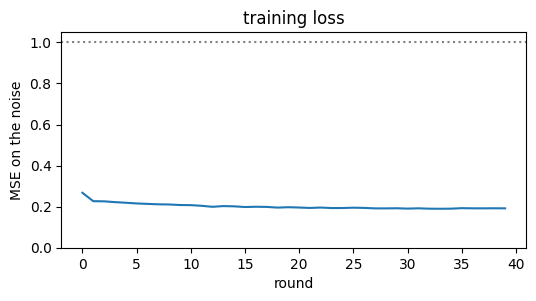

In [9]:
def train_denoiser(model, x0, sched, rounds, reps=1, batch=256, lr=2e-3, seed=0, verbose=True):
    """Noise-prediction training. Each round: reps noisy copies of x0 with fresh steps and noise, one pass.
    Returns the mean loss of each round."""
    rng = np.random.default_rng(seed)
    data = np.tile(x0, (reps,) + (1,) * (x0.ndim - 1))
    steps = rounds * int(np.ceil(len(data) / batch))
    model.compile(optimizer=keras.optimizers.Adam(keras.optimizers.schedules.CosineDecay(lr, steps)), loss="mse")
    history = []
    for r in range(rounds):
        t = rng.integers(1, sched["T"] + 1, size=len(data))            # a random step for every example
        eps = rng.standard_normal(data.shape).astype("float32")        # the noise
        x_t = q_sample(data, t, eps, sched)                            # mix
        h = model.fit([x_t, t], eps, batch_size=batch, epochs=1, verbose=0)   # predict the noise, MSE
        history.append(h.history["loss"][0])
        if verbose and (r % max(1, rounds // 8) == 0 or r == rounds - 1):
            print(f"round {r + 1:3d} / {rounds}   loss {history[-1]:.4f}")
    return history

t0 = time.time()
hist_a = train_denoiser(denoiser, X, SCHED, rounds=40, reps=10, batch=512, seed=SEED)
print(f"trained in {time.time() - t0:.0f} s: {40 * int(np.ceil(80000 / 512)):,} steps of batch 512")

plt.figure(figsize=(6, 2.8)); plt.plot(hist_a); plt.axhline(1.0, color="grey", ls=":"); plt.ylim(0, 1.05)
plt.xlabel("round"); plt.ylabel("MSE on the noise"); plt.title("training loss"); plt.show()

### Why we see this

The loss drops from near 1 to about 0.2 in the first couple of rounds and then hardly moves, although the
network keeps improving (you will see how much in Step 13). It cannot reach 0, because the question often
has no single answer: the same noisy point can be reached from many clean points with many noises, and
the best the network can do is the average of them. **A flat diffusion loss is normal**, and its value
tells you very little about how good the samples are.

---
## Step 10 - The loss, one noise level at a time

The single number 0.2 is an average over all 1,000 noise levels. Split it up.

> **Predict:** where is the noise easiest to guess: at small t, where there is very little of it, or at
> large t, where the input is almost nothing but noise?

In [10]:
BUCKETS = [(1, 10), (11, 50), (51, 100), (101, 250), (251, 500), (501, 750), (751, 1000)]

def loss_by_timestep(model, x0, sched, buckets=BUCKETS, seed=0):
    """Mean squared error on the noise, for steps drawn from each (low, high) range."""
    rng = np.random.default_rng(seed)
    out = []
    for lo, hi in buckets:
        t = rng.integers(lo, hi + 1, size=len(x0))
        eps = rng.standard_normal(x0.shape).astype("float32")
        pred = model.predict([q_sample(x0, t, eps, sched), t], batch_size=1000, verbose=0)
        out.append(float(np.mean((pred - eps) ** 2)))
    return out

lbt_a = loss_by_timestep(denoiser, X_REAL, SCHED, seed=SEED)
print(f"{'steps':>12} {'noise weight':>13} {'loss':>8}")
for (lo, hi), l in zip(BUCKETS, lbt_a):
    print(f"{lo:5d} - {hi:4d} {SCHED['noise'][(lo + hi) // 2]:13.3f} {l:8.4f}")
print("measured on 2,000 points the network never trained on")

       steps  noise weight     loss
    1 -   10         0.026   0.9206
   11 -   50         0.108   0.6887
   51 -  100         0.247   0.5936
  101 -  250         0.524   0.5141
  251 -  500         0.873   0.1734
  501 -  750         0.990   0.0160
  751 - 1000         1.000   0.0006
measured on 2,000 points the network never trained on


### Why we see this

At the last steps the loss is almost 0: the input is nearly pure noise, so "the noise is the input" is
nearly right. That is an easy question, not a clever network. At the first steps the loss is close to
1.0, the know-nothing score. There the noise is tiny (weight about 0.03), smaller than the thickness of
the moons themselves, so the network cannot tell "noise" from "where this point happened to sit inside
its moon". And at every level the part of the noise that slides a point **along** its moon can never be
guessed, because the result is another perfectly good data point.

So a loss near 1 at small t is not a failure, and a loss near 0 at large t is not a success. One average
hides both facts.

---
## Step 11 - One big jump back

The forward formula can be solved for the clean point: if you know x<sub>t</sub> and the noise, then
clean = (x<sub>t</sub> − noise weight × noise) / signal weight. So from the network's noise guess you get
a guess of the clean point **in one jump**. Why not generate that way: start from noise, jump once, done?

> **Predict:** take real points, noise them to step 500, and jump back in one go. Will the guesses land on
> the moons? What does a network do when many answers are possible and it is scored by squared error?

 from step  signal   std of the guesses     off  divide by


       100   0.947          [0.92 0.5 ]   0.025     0.9471


       250   0.724          [0.7  0.31]   0.099     0.7239


       500   0.280          [0.25 0.11]   0.141     0.2803


       750   0.058          [0.19 0.19]   0.142     0.0579


      1000   0.006          [2.31 2.43]   1.776     0.0064
the data itself has std [0.97 0.55]


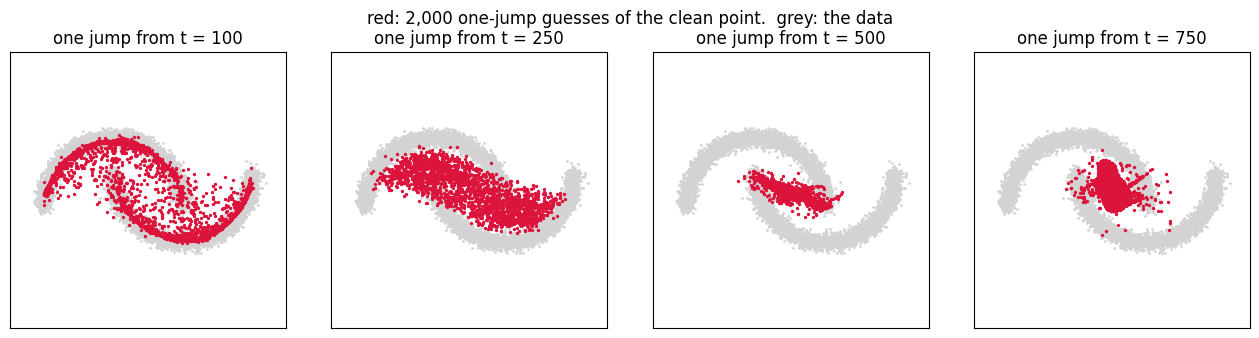

In [11]:
def one_jump(model, x_t, t, sched):
    """Guess the clean data from x_t in a single jump, using the network's noise guess."""
    tt = np.full(len(x_t), t, dtype="int32")
    eps_hat = model.predict([x_t, tt], batch_size=1000, verbose=0)
    return (x_t - sched["noise"][t] * eps_hat) / sched["signal"][t]

rng = np.random.default_rng(SEED)
eps = rng.standard_normal(X_REAL.shape).astype("float32")
jumps = {}
print(f"{'from step':>10} {'signal':>7} {'std of the guesses':>20} {'off':>7} {'divide by':>10}")
for t in (100, 250, 500, 750, 1000):
    x_t = q_sample(X_REAL, np.full(len(X_REAL), t), eps, SCHED)
    jumps[t] = one_jump(denoiser, x_t, t, SCHED)
    print(f"{t:10d} {SCHED['signal'][t]:7.3f} {str(jumps[t].std(0).round(2)):>20} {nearest_dist(jumps[t], X).mean():7.3f} {SCHED['signal'][t]:10.4f}")
print("the data itself has std", X.std(0).round(2))

fig, ax = plt.subplots(1, 4, figsize=(13, 3.4))
for a, t in zip(ax, (100, 250, 500, 750)):
    a.scatter(X[:, 0], X[:, 1], s=1, c="lightgrey"); a.scatter(jumps[t][:, 0], jumps[t][:, 1], s=2, c="crimson")
    lims(a, 2.2); a.set_title(f"one jump from t = {t}")
plt.suptitle("red: 2,000 one-jump guesses of the clean point.  grey: the data"); plt.tight_layout(); plt.show()

### Why we see this

From step 100 the one-jump guesses are good: little was lost, so there is one sensible answer. From step
500 the guesses huddle in the middle of the picture, with a spread far smaller than the data's, mostly
**between** the moons where there is no data at all. Each guess is the **average** of all the clean points
that could have led to that noisy point. An average of points on two crescents is a point on neither.
For images, the average of many plausible pictures is a blur. This is the one fact that explains why
diffusion takes small steps.

From step 1,000 the guesses are worse than useless: their spread is larger than the data's by a wide
margin. Look at the last column. The formula divides by the signal weight, which is 0.0064 there, so any
small error in the noise guess is multiplied by about 157. That is why some systems train the network to
predict the clean data, or a blend of clean data and noise called **v**, instead of the noise: those
targets stay well-behaved where the noise target does not.

---
## Step 12 - The sampler: many small steps

The sampler never trusts the big jump. At each step from t = 1,000 down to 1 it does three things:

1. ask the network for the noise, and turn that into a **guess of the clean point** (the one-jump guess);
2. move to a blend: `to_clean[t]` × the guess + `to_current[t]` × where it is now;
3. add a little **fresh noise**, of size `sigma[t]`.

The three numbers come from the schedule (Step 3 computed them). This is **ancestral sampling**, the
sampler of the 2020 paper. At t = 1 the weights are exactly 1, 0 and 0: the last step returns the guess
and adds nothing.

`clip` is for images: it holds the guess of the clean image inside the legal range (-1 ... 1). The moons
have no such range, so Part A leaves it off.

> **Predict:** at step 1,000, what fraction of the way towards its guess does the sampler move: half, a
> tenth, or far less than a hundredth? (You know the guess at that step is nearly worthless.)

    t   to_clean  to_current    sigma
 1000    0.00013     0.98995   0.1414
  750    0.00088     0.99241   0.1226
  500    0.00307     0.99411   0.1002
  250    0.00772     0.99188   0.0709
  100    0.01908     0.98090   0.0451
   10    0.14727     0.85273   0.0154
    2    0.54529     0.45471   0.0074
    1    1.00000     0.00000   0.0000



2,000 points, 1,000 network calls: 2.6 s


2,000 fresh real points            off 0.009 | miss 0.017 | further than 0.1 from any moon:   0.0% | std [0.97 0.55]


ancestral sampler, 1,000 steps     off 0.011 | miss 0.017 | further than 0.1 from any moon:   1.1% | std [0.95 0.56]


one jump from step 500             off 0.141 | miss 0.469 | further than 0.1 from any moon:  66.8% | std [0.25 0.11]


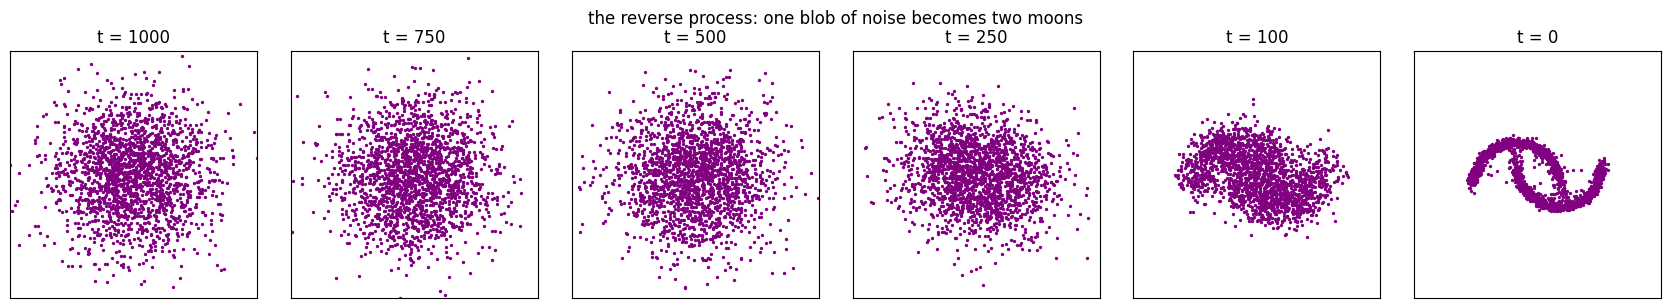

In [12]:
def sample(model, sched, n, shape=(2,), seed=0, fresh_noise=True, clip=None, keep=()):
    """Ancestral sampling. Start from pure noise and walk from t = T down to t = 1.
    Returns (samples, snapshots) where snapshots[t] is the batch after reaching step t, for every t in keep."""
    rng = np.random.default_rng(seed)
    x = rng.standard_normal((n,) + tuple(shape)).astype("float32")           # pure noise: step T
    snaps = {sched["T"]: x.copy()} if sched["T"] in keep else {}
    for t in range(sched["T"], 0, -1):
        eps_hat = model.predict_on_batch([x, np.full(n, t, dtype="int32")])  # 1. predict the noise ...
        x0_hat = (x - sched["noise"][t] * eps_hat) / sched["signal"][t]      #    ... and guess the clean data
        if clip is not None:
            x0_hat = np.clip(x0_hat, -clip, clip)
        x = sched["to_clean"][t] * x0_hat + sched["to_current"][t] * x       # 2. step a little towards the guess
        if fresh_noise:
            x = x + sched["sigma"][t] * rng.standard_normal(x.shape)         # 3. add fresh noise
        x = x.astype("float32")
        if t - 1 in keep:
            snaps[t - 1] = x.copy()
    return x, snaps

print(f"{'t':>5} {'to_clean':>10} {'to_current':>11} {'sigma':>8}")
for t in (1000, 750, 500, 250, 100, 10, 2, 1):
    print(f"{t:5d} {SCHED['to_clean'][t]:10.5f} {SCHED['to_current'][t]:11.5f} {SCHED['sigma'][t]:8.4f}")

t0 = time.time()
KEEP = (1000, 750, 500, 250, 100, 0)
gen, path = sample(denoiser, SCHED, 2000, seed=SEED, keep=KEEP)
print(f"\n2,000 points, 1,000 network calls: {time.time() - t0:.1f} s")
score(X_REAL2, "2,000 fresh real points")
SAMPLE_SCORE = score(gen, "ancestral sampler, 1,000 steps")
score(jumps[500], "one jump from step 500")

fig, ax = plt.subplots(1, 6, figsize=(17, 3.1))
for a, t in zip(ax, KEEP):
    a.scatter(path[t][:, 0], path[t][:, 1], s=2, c="purple"); lims(a, 3.2); a.set_title(f"t = {t}")
plt.suptitle("the reverse process: one blob of noise becomes two moons"); plt.tight_layout(); plt.show()

### Why we see this

At step 1,000 the sampler moves 0.00013 of the way towards its guess and keeps 0.99 of where it is. It
takes the guess as a faint hint of direction and no more. The weight on the guess grows as the guess
improves, and only at the very end does the sampler believe it outright.

The result is the two moons. The generated points lie about as close to the training data as fresh real
points do (0.011 against 0.009), they cover the moons as well as real points do (0.017 for both), and
about 1 in 100 strays more than 0.1 from a moon. Compare with the one-jump line: same network, same
weights, used once instead of a thousand times, and two thirds of the points sit off the moons.

In the pictures almost nothing seems to happen from 1,000 down to 500: the blob stays a blob. By 250 it
has stretched, at 100 the two moons are there but fuzzy, and the last 100 steps sharpen them. High-noise steps decide **which
moon and roughly where**; low-noise steps decide **exactly where**. In an image model the same split is
layout first, texture last.

The cost: 1,000 network calls for one batch. A GAN or a VAE decoder would make it in one.

---
## Step 13 - Can you judge it by the loss?

Step 9 said the loss goes flat early while the network keeps improving. Test that claim. Train a second,
identical network for **4 rounds instead of 40**, and compare both the loss and the samples.

> **Predict:** the 4-round network's loss will be within about 0.03 of the 40-round network's. Will its
> samples be about as good, too?

final training loss: 40 rounds 0.1917 | 4 rounds 0.2218



40 rounds of training              off 0.011 | miss 0.017 | further than 0.1 from any moon:   1.1% | std [0.95 0.56]


4 rounds of training               off 0.127 | miss 0.033 | further than 0.1 from any moon:  41.5% | std [0.94 0.54]



       steps  40 rounds  4 rounds
    1 -   10     0.9206    1.0137
   11 -   50     0.6887    0.9884
   51 -  100     0.5936    0.8186
  101 -  250     0.5141    0.5609
  251 -  500     0.1734    0.1752
  501 -  750     0.0160    0.0168
  751 - 1000     0.0006    0.0016


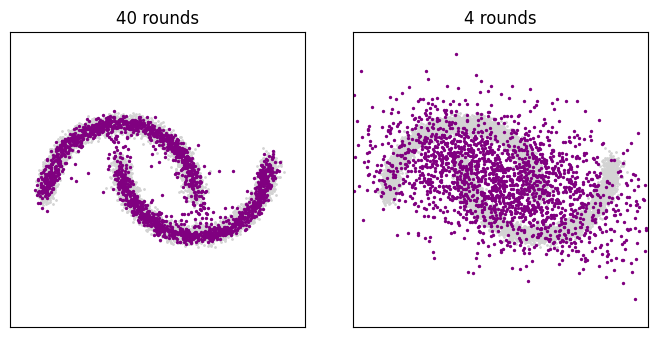

In [13]:
keras.utils.set_random_seed(SEED)
hasty = build_denoiser(name="denoiser_4_rounds")
hist_hasty = train_denoiser(hasty, X, SCHED, rounds=4, reps=10, batch=512, seed=SEED, verbose=False)
gen_hasty, _ = sample(hasty, SCHED, 2000, seed=SEED)
print(f"final training loss: 40 rounds {hist_a[-1]:.4f} | 4 rounds {hist_hasty[-1]:.4f}")
print()
score(gen, "40 rounds of training")
HASTY_SCORE = score(gen_hasty, "4 rounds of training")

lbt_hasty = loss_by_timestep(hasty, X_REAL, SCHED, seed=SEED)
print()
print(f"{'steps':>12} {'40 rounds':>10} {'4 rounds':>9}")
for (lo, hi), a, b in zip(BUCKETS, lbt_a, lbt_hasty):
    print(f"{lo:5d} - {hi:4d} {a:10.4f} {b:9.4f}")

fig, ax = plt.subplots(1, 2, figsize=(7, 3.4))
for a, g, name in ((ax[0], gen, "40 rounds"), (ax[1], gen_hasty, "4 rounds")):
    a.scatter(X[:, 0], X[:, 1], s=1, c="lightgrey"); a.scatter(g[:, 0], g[:, 1], s=2, c="purple"); lims(a, 2.2); a.set_title(name)
plt.tight_layout(); plt.show()

### Why we see this

The two losses differ in the second decimal place. The samples differ completely: after 4 rounds a
large share of the points lie off the moons, in a haze round them; after 40 rounds almost none do.

The table says where the difference hides. At steps above 250 the two networks score the same: the easy,
high-noise part was learnt in the first few rounds, and it carries most of the average. The gain from
the extra training is all at **small t**, where the loss is large for both and falls only a little. Those
are the steps that place a point exactly on its moon. A small change in a number near 1 was the whole
difference between a haze and a clean crescent.

This is why nobody tunes a diffusion model by its training loss alone. You sample, and you look, or you
measure the samples, as `score` does here.

---
## Step 14 - What is the fresh noise for?

Step 3 of the sampler adds noise back, which looks perverse in a procedure meant to remove it. Leave it
out and see.

> **Predict:** with `fresh_noise=False` every step moves towards the average guess and nothing ever
> spreads the points out again. Do you get (a) sharper moons, (b) the same moons, or (c) something much
> smaller than the moons?

with fresh noise                   off 0.011 | miss 0.017 | further than 0.1 from any moon:   1.1% | std [0.95 0.56]


without fresh noise                off 0.009 | miss 0.968 | further than 0.1 from any moon:   0.1% | std [0.02 0.02]


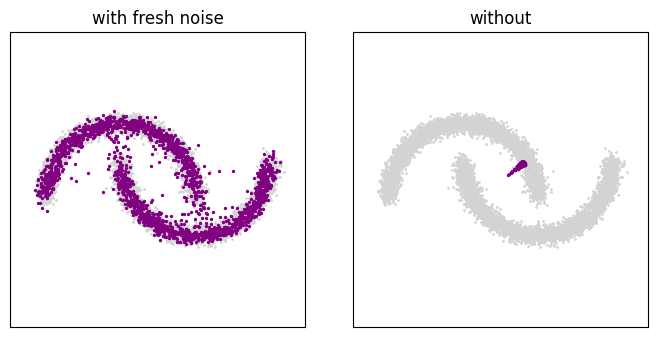

In [14]:
gen_quiet, _ = sample(denoiser, SCHED, 2000, seed=SEED, fresh_noise=False)
score(gen, "with fresh noise")
QUIET_SCORE = score(gen_quiet, "without fresh noise")

fig, ax = plt.subplots(1, 2, figsize=(7, 3.4))
for a, g, name in ((ax[0], gen, "with fresh noise"), (ax[1], gen_quiet, "without")):
    a.scatter(X[:, 0], X[:, 1], s=1, c="lightgrey"); a.scatter(g[:, 0], g[:, 1], s=2, c="purple"); lims(a, 2.2); a.set_title(name)
plt.tight_layout(); plt.show()

### Why we see this

Without the fresh noise the whole batch collapses to a small clump: the spread of the samples falls from
about (0.95, 0.55) to a few hundredths. Every step moves each point towards an **average** of the
places it might belong, and an average is always nearer the middle than the things averaged. Do that a
thousand times with nothing to restore the spread and the cloud shrinks to one spot. The "miss" score
says it plainly: real points are now nearly a whole unit from the nearest sample.

The fresh noise is what turns "move towards the average" into "pick one of the possibilities". It is the
sampler's dice. The reverse process is random at every step, and that is where the variety of the
samples comes from.

(There **are** samplers with no added noise. They do not use this arithmetic with the noise deleted;
they use different weights that keep the spread right. Chapter 51 builds one.)

---
## Step 15 - What is the time input for?

Train the same network again with the time embedding multiplied by zero, so that it sees the noisy point
and nothing else. Same data, same schedule, same number of steps.

> **Predict:** a point at (1.5, 1.5) is far outside the moons. With the time, the network knows whether
> that is a clean point with a lot of noise on it or... what? Without the time, what must it do?

trained in 25 s | final loss with time 0.1917 | without time 0.2528



       steps  with time   without
    1 -   10     0.9206    1.2570
   11 -   50     0.6887    1.1913
   51 -  100     0.5936    0.8872
  101 -  250     0.5141    0.5749
  251 -  500     0.1734    0.1859
  501 -  750     0.0160    0.0399
  751 - 1000     0.0006    0.0263


with the time input                off 0.011 | miss 0.017 | further than 0.1 from any moon:   1.1% | std [0.95 0.56]


without the time input             off 0.087 | miss 0.050 | further than 0.1 from any moon:  35.1% | std [0.58 0.45]


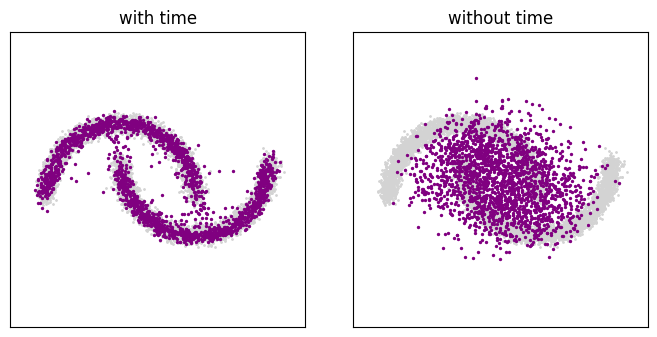

In [15]:
keras.utils.set_random_seed(SEED)
blind = build_denoiser(use_time=False, name="denoiser_without_time")
assert blind.count_params() == MLP_HAND                       # same size: the time weights are there but unused
t0 = time.time()
hist_blind = train_denoiser(blind, X, SCHED, rounds=40, reps=10, batch=512, seed=SEED, verbose=False)
print(f"trained in {time.time() - t0:.0f} s | final loss with time {hist_a[-1]:.4f} | without time {hist_blind[-1]:.4f}")

lbt_blind = loss_by_timestep(blind, X_REAL, SCHED, seed=SEED)
print(f"\n{'steps':>12} {'with time':>10} {'without':>9}")
for (lo, hi), a, b in zip(BUCKETS, lbt_a, lbt_blind):
    print(f"{lo:5d} - {hi:4d} {a:10.4f} {b:9.4f}")

gen_blind, _ = sample(blind, SCHED, 2000, seed=SEED)
print()
score(gen, "with the time input")
BLIND_SCORE = score(gen_blind, "without the time input")

fig, ax = plt.subplots(1, 2, figsize=(7, 3.4))
for a, g, name in ((ax[0], gen, "with time"), (ax[1], gen_blind, "without time")):
    a.scatter(X[:, 0], X[:, 1], s=1, c="lightgrey"); a.scatter(g[:, 0], g[:, 1], s=2, c="purple"); lims(a, 2.2); a.set_title(name)
plt.tight_layout(); plt.show()

### Why we see this

Without the time, the network has to give one answer for a noisy point whatever its noise level, so it
learns a compromise that is wrong at most levels. The table shows where it hurts, and the samples show
the result. Read the scores printed above: the blind model is worse on the numbers that measure whether
the points are on the moons and whether the moons are covered.

The blind network is not helpless: the position of a point hints at its noise level (a point far from
both moons must be very noisy), which is why it still draws something moon-like. The hint is not enough.
The trap to remember is the silent version of this experiment: a time input that is wired up but
**never reaches the layers**, or that is fed the wrong numbers. Nothing crashes. The samples are poor.

---
## Step 16 - The shortcut that does not work

A thousand network calls is slow. The obvious saving: visit only every tenth step (1,000, 990, 980, ...),
using the same weights as before. A hundred calls instead of a thousand.

> **Predict:** the weights `to_clean`, `to_current` and `sigma` at step t were worked out for a move from
> t to t − 1. If you use them for a move from t to t − 10, has enough noise been removed at each move?
> What will the final cloud look like?

1,000 steps                        off 0.011 | miss 0.017 | further than 0.1 from any moon:   1.1% | std [0.95 0.56]


every 10th step, same weights      off 0.209 | miss 0.031 | further than 0.1 from any moon:  49.1% | std [0.95 0.81]


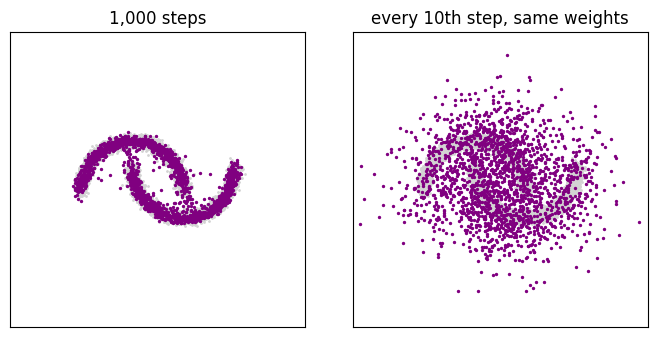

In [16]:
def sample_skipping(model, sched, n, stride, seed=0):
    """WRONG ON PURPOSE: visit every stride-th step but keep the one-step weights."""
    rng = np.random.default_rng(seed)
    x = rng.standard_normal((n, 2)).astype("float32")
    for t in range(sched["T"], 0, -stride):
        eps_hat = model.predict_on_batch([x, np.full(n, t, dtype="int32")])
        x0_hat = (x - sched["noise"][t] * eps_hat) / sched["signal"][t]
        x = sched["to_clean"][t] * x0_hat + sched["to_current"][t] * x + sched["sigma"][t] * rng.standard_normal(x.shape)
        x = x.astype("float32")
    return x

gen_skip = sample_skipping(denoiser, SCHED, 2000, stride=10, seed=SEED)
score(gen, "1,000 steps")
SKIP_SCORE = score(gen_skip, "every 10th step, same weights")

fig, ax = plt.subplots(1, 2, figsize=(7, 3.4))
for a, g, name in ((ax[0], gen, "1,000 steps"), (ax[1], gen_skip, "every 10th step, same weights")):
    a.scatter(X[:, 0], X[:, 1], s=1, c="lightgrey"); a.scatter(g[:, 0], g[:, 1], s=2, c="purple"); lims(a, 3.2); a.set_title(name)
plt.tight_layout(); plt.show()

### Why we see this

The cloud never comes into focus: it is still a wide blob when the loop ends. Each move removed one
step's worth of noise and then the loop jumped ten steps ahead, telling the network "this is step 990"
about a point that is still as noisy as step 999. By the end the network is being told "almost clean"
about points that are almost pure noise.

Fewer steps **are** possible, and Chapter 51 does it properly: the weights have to be recomputed for the
bigger stride ("respacing"), or a different sampler used. The rule: **the schedule the sampler uses must
match the steps the sampler actually takes.**

---
# Part B - The same thing on small digits

## Step 17 - MNIST, shrunk and scaled to -1 ... 1

Nothing in `make_schedule`, `q_sample`, `train_denoiser` or `sample` knows that the data had two numbers
per example. Give them 256 numbers per example (a 16 × 16 image) and they work unchanged. Only the
network must change, because an MLP is the wrong tool for an image.

The digits are padded from 28 to 32 pixels and averaged down to **16 × 16** to fit the CPU budget, and
scaled from 0 ... 255 to **-1 ... 1**.

> **Predict:** the schedule ends at signal weight 0.0064. On a digit whose pixels are -1 (paper) or +1
> (ink), is the digit readable at t = 250, where the signal weight is 0.72? At t = 500, where it is 0.28?

images: (30000, 16, 16, 1) float32 | min -1.0 | max 1.0 | mean -0.798


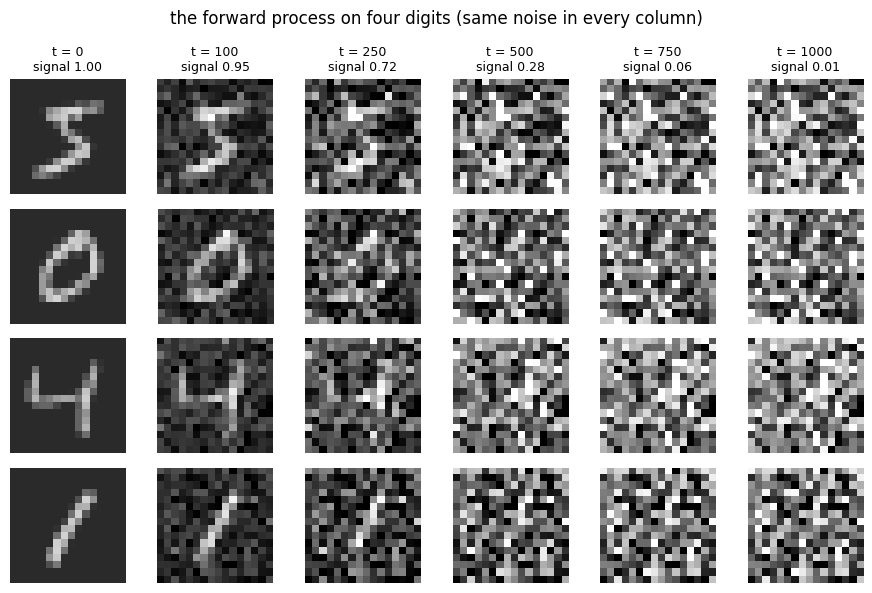

In [17]:
(x_train, _), _ = keras.datasets.mnist.load_data()
N_IMG = 30_000
imgs = x_train[:N_IMG].astype("float32") / 127.5 - 1.0                       # 0..255  ->  -1..1
imgs = np.pad(imgs, ((0, 0), (2, 2), (2, 2)), constant_values=-1.0)          # 28 -> 32, paper is -1
imgs = imgs.reshape(N_IMG, 16, 2, 16, 2).mean(axis=(2, 4))[..., None]         # 32 -> 16 by averaging 2 x 2
HELD = x_train[50_000:50_500].astype("float32") / 127.5 - 1.0                # 500 digits kept out of training
HELD = np.pad(HELD, ((0, 0), (2, 2), (2, 2)), constant_values=-1.0).reshape(500, 16, 2, 16, 2).mean(axis=(2, 4))[..., None]
print("images:", imgs.shape, imgs.dtype, "| min", imgs.min(), "| max", imgs.max(), "| mean", round(float(imgs.mean()), 3))

rng = np.random.default_rng(SEED)
eps_img = rng.standard_normal(imgs[:4].shape).astype("float32")
levels = (0, 100, 250, 500, 750, 1000)
fig, ax = plt.subplots(4, len(levels), figsize=(9, 6))
for j, t in enumerate(levels):
    noisy = q_sample(imgs[:4], np.full(4, t), eps_img, SCHED)
    for i in range(4):
        ax[i, j].imshow(noisy[i, :, :, 0], cmap="gray", vmin=-1.5, vmax=1.5); ax[i, j].axis("off")
    ax[0, j].set_title(f"t = {t}\nsignal {SCHED['signal'][t]:.2f}", fontsize=9)
plt.suptitle("the forward process on four digits (same noise in every column)"); plt.tight_layout(); plt.show()

### Why we see this

The digit is easy to read at t = 100, hard to read at 250, and gone by 500. These tiny
images lose their content earlier than a large photograph would under the same schedule: a 16 × 16 digit
has few pixels to average over, so a given amount of noise hides it sooner. That is the observation
behind the cosine schedule of Step 4.

---
## Step 18 - The denoiser: Chapter 47's U-Net with a clock

The network must return something the same shape as its input, pixel for pixel, and it must see both
the whole digit and the exact pixels. That is the job the U-Net of Chapter 47 was built for. Here is
that network (16, 32, 64 filters, two poolings, two bridges) with three changes:

1. a second input, the step t, turned into a 32-number embedding and passed through one Dense layer of 64;
2. in **every** convolution block, a Dense layer turns that 64-number time vector into one number per
   channel, which is added to the feature maps between the two convolutions;
3. the head is a 1 × 1 convolution to **1 channel with no activation**: the noise guess.

> **Predict:** Chapter 47's U-Net with a one-channel head has 116,753 parameters. The time path adds a
> Dense(32 → 64) and, for the five blocks with 16, 32, 64, 32 and 16 channels, a Dense(64 → channels)
> each. How many parameters is that, and what is the new total?

In [18]:
def conv_block(x, filters, temb, name):
    """Two 3x3 convolutions, with the time vector added (one number per channel) between them."""
    x = layers.Conv2D(filters, 3, padding="same", activation="relu", name=name + "_conv1")(x)
    tvec = layers.Dense(filters, name=name + "_time")(temb)                 # (batch, filters)
    x = layers.Add(name=name + "_add_time")([x, layers.Reshape((1, 1, filters), name=name + "_t11")(tvec)])
    x = layers.Conv2D(filters, 3, padding="same", activation="relu", name=name + "_conv2")(x)
    return x

def build_unet_denoiser(input_shape=(16, 16, 1), base=16, depth=2, emb_dim=32, name="unet_denoiser"):
    """Chapter 47's U-Net, extended with a time embedding. Predicts the noise: output shape = input shape.
    Height and width must be divisible by 2**depth."""
    x_in = layers.Input(shape=input_shape, name="x_t")
    t_in = layers.Input(shape=(), dtype="int32", name="t")
    temb = TimeEmbedding(emb_dim, name="time_embedding")(t_in)
    temb = layers.Dense(4 * base, activation="swish", name="time_dense")(temb)
    x, bridges = x_in, []
    for i in range(depth):                                       # the contracting path
        x = conv_block(x, base * 2 ** i, temb, f"down{i + 1}")
        bridges.append(x)
        x = layers.MaxPooling2D(2, name=f"pool{i + 1}")(x)
    x = conv_block(x, base * 2 ** depth, temb, "bottom")         # the bottom of the U
    for i in reversed(range(depth)):                             # the expanding path
        f = base * 2 ** i
        x = layers.Conv2DTranspose(f, 2, strides=2, padding="same", name=f"up{i + 1}")(x)
        x = layers.Concatenate(name=f"bridge{i + 1}")([bridges[i], x])
        x = conv_block(x, f, temb, f"dec{i + 1}")
    out = layers.Conv2D(input_shape[-1], 1, name="noise")(x)     # no activation
    return keras.Model([x_in, t_in], out, name=name)

conv = lambda cin, cout, k=3: (k * k * cin + 1) * cout
unet_47 = (conv(1, 16) + conv(16, 16) + conv(16, 32) + conv(32, 32) + conv(32, 64) + conv(64, 64)     # down1, down2, bottom
           + conv(64, 32, 2) + conv(64, 32) + conv(32, 32)                                          # up2, dec2
           + conv(32, 16, 2) + conv(32, 16) + conv(16, 16)                                          # up1, dec1
           + conv(16, 1, 1))                                                                        # head
time_dense = (32 + 1) * 64
time_into_blocks = sum((64 + 1) * f for f in (16, 32, 64, 32, 16))
UNET_HAND = unet_47 + time_dense + time_into_blocks
print(f"Chapter 47's U-Net, one output channel : {unet_47:,}")
print(f"time Dense (32 + 1) x 64               : {time_dense:,}")
print(f"time into five blocks, 65 x 160        : {time_into_blocks:,}")
print(f"hand count                             : {UNET_HAND:,}")

keras.utils.set_random_seed(SEED)
unet = build_unet_denoiser()
assert unet_47 == 116_753 and unet.count_params() == UNET_HAND == 129_265
print(f"Keras count                            : {unet.count_params():,}")
print(f"share of the weights spent on time     : {100 * (time_dense + time_into_blocks) / UNET_HAND:.1f}%")
for name in ("down1_conv2", "down2_conv2", "bottom_conv2", "dec2_conv2", "dec1_conv2", "noise"):
    print(f"  {name:13s} {unet.get_layer(name).output.shape}")

Chapter 47's U-Net, one output channel : 116,753
time Dense (32 + 1) x 64               : 2,112
time into five blocks, 65 x 160        : 10,400
hand count                             : 129,265
Keras count                            : 129,265
share of the weights spent on time     : 9.7%
  down1_conv2   (None, 16, 16, 16)
  down2_conv2   (None, 8, 8, 32)
  bottom_conv2  (None, 4, 4, 64)
  dec2_conv2    (None, 8, 8, 32)
  dec1_conv2    (None, 16, 16, 16)
  noise         (None, 16, 16, 1)


### Why we see this

2,112 + 10,400 = 12,512 parameters for the clock, 9.7% of **129,265**. The shapes go 16 → 8 → 4 and back
to 16, and the output is `(16, 16, 1)`: a noise guess for every pixel.

Adding one number per channel is a small thing with a large effect. It lets the time shift every
channel up or down before the ReLU, so the same filters can behave differently at different noise
levels: cautious smoothing at high noise, fine edge work at low noise.

Large image models use the same plan with more of everything: several resolutions, residual blocks,
attention layers at the small resolutions, and often a transformer over patches in place of the U-Net.

---
## Step 19 - Train on the digits

The same `train_denoiser`, with one noisy copy of the 30,000 digits per round.

> **Predict:** in Part A the loss settled near 0.2. A digit has 256 numbers and far more structure than
> a moon (most pixels are plain paper). Will the loss settle higher or lower?

In [19]:
t0 = time.time()
hist_b = train_denoiser(unet, imgs, SCHED, rounds=18, reps=1, batch=128, seed=SEED)
TRAIN_B = time.time() - t0
print(f"trained in {TRAIN_B:.0f} s: {18 * int(np.ceil(N_IMG / 128)):,} steps of batch 128")

lbt_b = loss_by_timestep(unet, HELD, SCHED, seed=SEED)
print(f"\n{'steps':>12} {'loss (digits)':>14} {'loss (moons)':>13}")
for (lo, hi), b, a in zip(BUCKETS, lbt_b, lbt_a):
    print(f"{lo:5d} - {hi:4d} {b:14.4f} {a:13.4f}")
print("digits: measured on 500 digits the network never trained on")

round   1 / 18   loss 0.1929


round   3 / 18   loss 0.0604


round   5 / 18   loss 0.0531


round   7 / 18   loss 0.0496


round   9 / 18   loss 0.0452


round  11 / 18   loss 0.0439


round  13 / 18   loss 0.0429


round  15 / 18   loss 0.0423


round  17 / 18   loss 0.0411


round  18 / 18   loss 0.0420
trained in 98 s: 4,230 steps of batch 128



       steps  loss (digits)  loss (moons)
    1 -   10         0.3152        0.9206
   11 -   50         0.1828        0.6887
   51 -  100         0.1323        0.5936
  101 -  250         0.0897        0.5141
  251 -  500         0.0369        0.1734
  501 -  750         0.0049        0.0160
  751 - 1000         0.0012        0.0006
digits: measured on 500 digits the network never trained on


### Why we see this

The loss settles far lower than on the moons, around 0.04. That is not because the image model is
better. An image is mostly predictable: paper is paper, strokes are smooth, and 256 pixels share one
picture, so the network can work out much more of the noise. Losses from different data sets cannot be
compared.

The pattern across noise levels is the same as before: hardest when the noise is faint, easiest when it
is nearly everything. Again the loss curve went flat after a few rounds. Whether the samples are any
good, the loss does not say. You have to look.

---
## Step 20 - Sample digits, and be honest about them

The same `sample` function, with `shape=(16, 16, 1)` and `clip=1.0` so that every guess of the clean
image stays inside -1 ... 1.

> **Predict:** this network trained for about a minute and a half. Will its digits be (a) clean, (b) a
> grey smear like the average of many digits, or (c) made of definite strokes that are often broken or
> not quite digits?

32 digits, 1,000 network calls: 5.2 s
sample range: -1.0 to 1.0
share of pixels that are ink: real digits 9.9% | generated 8.9%


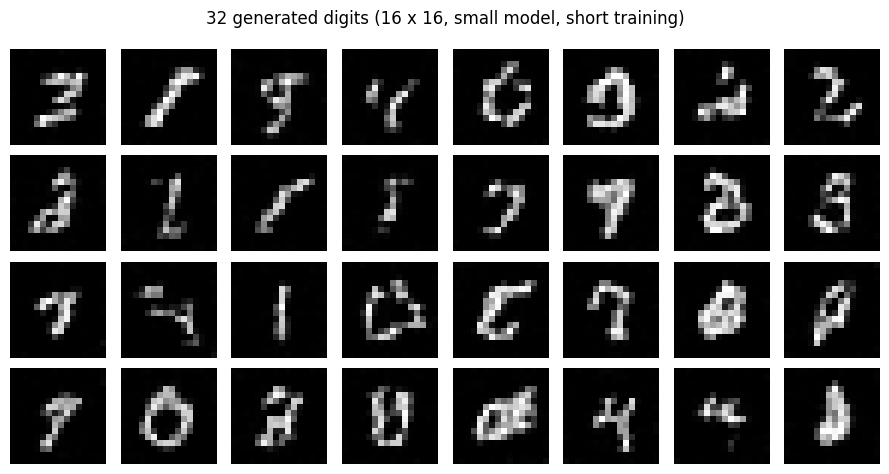

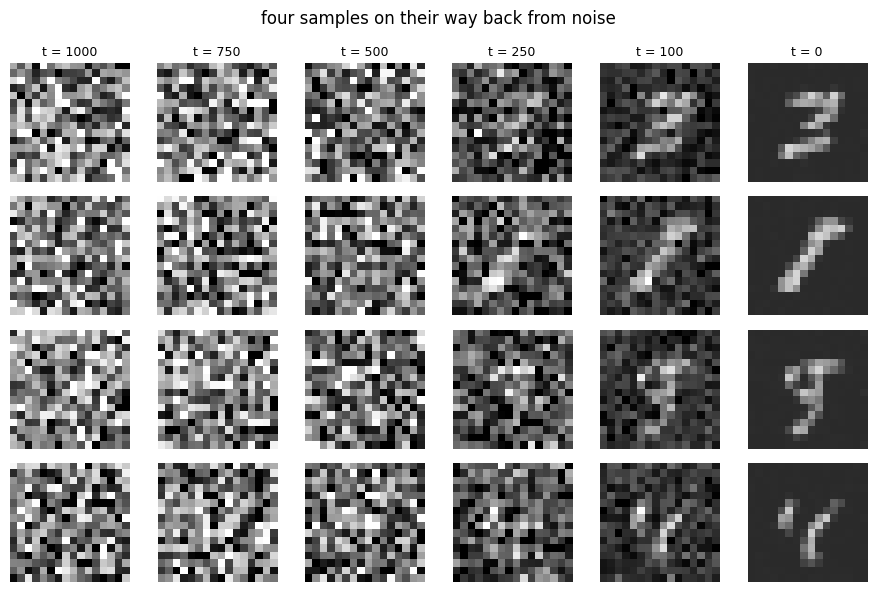

In [20]:
t0 = time.time()
KEEP_B = (1000, 750, 500, 250, 100, 0)
digits, dpath = sample(unet, SCHED, 32, shape=(16, 16, 1), seed=SEED, clip=1.0, keep=KEEP_B)
SAMPLE_B = time.time() - t0
print(f"32 digits, 1,000 network calls: {SAMPLE_B:.1f} s")
print("sample range:", round(float(digits.min()), 2), "to", round(float(digits.max()), 2))
ink_real = float((imgs > 0).mean()); ink_gen = float((digits > 0).mean())
print(f"share of pixels that are ink: real digits {100 * ink_real:.1f}% | generated {100 * ink_gen:.1f}%")

fig, ax = plt.subplots(4, 8, figsize=(9, 4.8))
for a, im in zip(ax.ravel(), digits):
    a.imshow(im[:, :, 0], cmap="gray", vmin=-1, vmax=1); a.axis("off")
plt.suptitle("32 generated digits (16 x 16, small model, short training)"); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(4, len(KEEP_B), figsize=(9, 6))
for j, t in enumerate(KEEP_B):
    for i in range(4):
        ax[i, j].imshow(dpath[t][i, :, :, 0], cmap="gray", vmin=-1.5, vmax=1.5); ax[i, j].axis("off")
    ax[0, j].set_title(f"t = {t}", fontsize=9)
plt.suptitle("four samples on their way back from noise"); plt.tight_layout(); plt.show()

### Why we see this

Look at the grid and count for yourself. In the author's run about half of the 32 are digits you would
read without hesitation (a 3, several 1s and 7s, a 2, some 0s, a 4). The rest are digit-like or broken:
a loop that does not close, strokes that do not join, two digits fused into one. All of them are a little
soft, as any 16 × 16 picture is. That is answer (c), and it is characteristic. An under-trained
autoencoder gives a grey smear, because it outputs an average. An under-trained diffusion model commits
to one possibility at every step, so it draws **definite strokes, some of them wrong**. Nobody would call
these good digits. They are what a 129,265-weight network learns in a minute and a half.

In the trajectory nothing is visible down to t = 500. At 250 a pale shape has appeared in roughly the
right place: the layout has been decided. At 100 the digit is plain under the noise, and the last hundred
steps clean it.

What would make them better, in order of effect: more training (hours, not a minute), a wider network
with attention at the 4 × 4 level, an average of the weights over the last part of training (every real
system uses one), and 28 × 28 input. Chapter 51 adds the class label, which helps more than you might
expect.

---
## Step 21 - Is it copying?

A common belief is that a diffusion model stores its training images and pastes them back. Check: for
each generated digit, find the **nearest training digit** (by pixel distance) and compare. As a yardstick,
do the same for 32 real digits that were never in the training set.

> **Predict:** if the model were retrieving training images, how far would each sample be from its
> nearest training image? How far do you expect a genuinely new digit to be?

RMS pixel distance to the nearest of 30,000 training digits (pixels run from -1 to 1):
  32 generated digits    : mean 0.267 | smallest 0.077
  32 held-out real digits: mean 0.201 | smallest 0.067


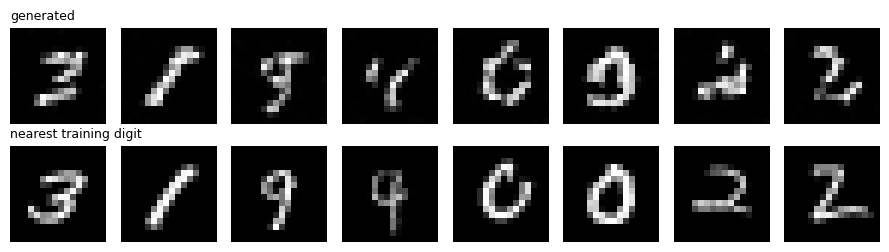


whole notebook: 186 s


In [21]:
def nearest_training(batch, train):
    a = batch.reshape(len(batch), -1); b = train.reshape(len(train), -1)
    d2 = (a ** 2).sum(1)[:, None] - 2 * a @ b.T + (b ** 2).sum(1)[None, :]
    idx = d2.argmin(axis=1)
    return idx, np.sqrt(np.maximum(d2[np.arange(len(a)), idx], 0) / a.shape[1])     # RMS pixel difference

idx_g, d_g = nearest_training(digits, imgs)
idx_h, d_h = nearest_training(HELD[:32], imgs)
print(f"RMS pixel distance to the nearest of {N_IMG:,} training digits (pixels run from -1 to 1):")
print(f"  32 generated digits    : mean {d_g.mean():.3f} | smallest {d_g.min():.3f}")
print(f"  32 held-out real digits: mean {d_h.mean():.3f} | smallest {d_h.min():.3f}")

fig, ax = plt.subplots(2, 8, figsize=(9, 2.6))
for j in range(8):
    ax[0, j].imshow(digits[j, :, :, 0], cmap="gray", vmin=-1, vmax=1); ax[0, j].axis("off")
    ax[1, j].imshow(imgs[idx_g[j], :, :, 0], cmap="gray", vmin=-1, vmax=1); ax[1, j].axis("off")
ax[0, 0].set_title("generated", fontsize=9, loc="left"); ax[1, 0].set_title("nearest training digit", fontsize=9, loc="left")
plt.tight_layout(); plt.show()
print(f"\nwhole notebook: {time.time() - t_start:.0f} s")

### Why we see this

On average the samples are **further** from their nearest training digit (0.27) than genuinely new real
digits are (0.20), and the closest sample of all (0.08) is no closer than the closest real one (0.07):
simple shapes such as a 1 always have a near twin. The nearest neighbours in the picture share a general
shape with the samples and differ stroke by stroke.
This model is not retrieving anything. It has 129,265 weights; the training set has 30,000 × 256 =
7,680,000 pixel values, about 59 times more.

That is not the whole story at full scale. Very large models trained on data sets containing many
copies of the same picture have been shown to reproduce some of those pictures closely. Generation is
not retrieval, and memorisation of duplicated training data is still a real, measured risk.

---
## Trials: change one thing at a time

Change the one line, **predict**, then rerun from that step. Write the observation in the last column.

| # | Change | Where | Predict | Observe |
|---|---|---|---|---|
| 1 | `SCHED = make_schedule(1000, "cosine")` and rerun from Step 3 with `clip=3.0` in the Part A samplers | Step 3 | The cosine schedule ends at a signal weight of almost exactly 0. What happens in `sample` when it divides by that, and why does the clip save it? | |
| 2 | `X, Y = make_points(500, seed=0)`: far fewer training points | Step 2 | Are the samples worse, or do they start to sit on the 500 training points? Compare "off" with the real points' "off". | |
| 3 | `build_denoiser(depth=2, width=32)` (comment out the assert) | Step 7 | Count the parameters first. Which gets worse: staying on the moons (off) or covering them (miss)? | |
| 4 | `lr=2e-2` in Step 9 | Step 9 | Ten times the learning rate. Does a regression with a fixed target blow up the way a GAN can? | |
| 5 | `rng.normal(0, 0.06, ...)` → `rng.normal(0, 0.2, ...)` in `make_points` (fatter moons) | Step 2 | What happens to the loss at steps 1 to 10, and why? | |
| 6 | `imgs = (imgs + 1) / 2; HELD = (HELD + 1) / 2` at the end of Step 17 (pixels 0 ... 1) | Step 17 | The model still trains. What is wrong with the samples' range and contrast? | |
| 7 | `build_unet_denoiser(base=8)` (comment out the assert) | Step 18 | About a quarter of the weights. Are the digits blurrier, or broken in a different way? | |
| 8 | `rounds=4` in Step 19 | Step 19 | Compare the loss with the 18-round loss, then compare the digits. Which changed more? | |

---
## Exercises

1. **Predict the clean point instead.** Change `train_denoiser` so that the target is `data` rather than
   `eps`, and change `sample` so that `x0_hat` is the network's output. Compare the loss by timestep with
   Step 10: at which end of the schedule is the new target easy, and at which end hard?
2. **A weighted loss.** The plain loss treats every step alike. Draw t so that steps 100 to 500 are chosen
   three times as often as the rest, and see whether the moons get sharper for the same training time.
3. **Count the calls.** Time one call of the U-Net on a batch of 32. Multiply by 1,000. Compare with the
   measured sampling time, and say what the difference is spent on.
4. **Three moons.** Add a third arc to `make_points`. Does the same network cope without any change? Look
   at the one-jump guesses from step 500 again: where is the average now?
5. **Start from a real point.** Take one real point, noise it to step 300 with `q_sample`, then run the
   sampler loop from 300 down to 1 (not from 1,000). Do this 200 times. How far do the results wander from
   the starting point, and do they ever change moon? Try 600. (This is the idea behind image-to-image
   editing.)
6. **The other variance.** Replace `sigma` in `make_schedule` by √β. The 2020 paper found both choices
   worked about equally well. What is different at t = 1, and what must you add to the sampler?

---
## Cheat sheet

| Thing | In one line |
|---|---|
| forward step | shrink by √(1 − β), add noise of variance β. No weights. |
| schedule | the list of β; DDPM (2020): 1,000 steps, 0.0001 to 0.02 |
| ᾱ<sub>t</sub> | product of (1 − β) up to step t: the share of signal variance left |
| one jump | x<sub>t</sub> = √ᾱ<sub>t</sub> · x<sub>0</sub> + √(1 − ᾱ<sub>t</sub>) · noise; the weights' squares add to 1 |
| SNR | ᾱ / (1 − ᾱ); linear schedule crosses 1 at step 260, cosine at 497 |
| data range | centred, about unit size; images in -1 ... 1 |
| network | input: x<sub>t</sub> and t; output: same shape as x<sub>t</sub>, no activation |
| time input | sinusoidal embedding → Dense → added in every block |
| training | random t in 1 ... T, random noise, `q_sample`, MSE between true and predicted noise |
| know-nothing loss | 1.0 (the variance of the noise) |
| loss by timestep | near 1 at small t, near 0 at large t; neither says the samples are good |
| one-jump guess | (x<sub>t</sub> − noise weight × predicted noise) / signal weight: an average, so a blur |
| sampler step | guess clean → blend guess and current point → add fresh noise; nothing added at t = 1 |
| no fresh noise | the samples collapse towards the middle |
| fewer steps | needs respaced weights or another sampler (Chapter 51), not skipping |
| cost | one network call per step, per batch |